# Auto Insurance Customer Lifetime Value — Regression Analysis

This notebook mirrors the structure of the Telco churn study, but for **regression**: predicting `Customer Lifetime Value` (CLV) for an auto-insurance book of business ([IBM Watson Marketing Customer Value dataset](https://www.kaggle.com/datasets/pankajjsh06/ibm-watson-marketing-customer-value-data), 9,134 customers, 24 columns). Each phase builds on the previous one.

| Phase | Approach | Key Additions |
|-------|----------|---------------|
| **Phase 1** | Sklearn baselines | Dummy, Linear Regression, Random Forest, Gradient Boosting — no tuning |
| **Phase 2** | Sklearn + tuning | `RandomizedSearchCV` on ElasticNet, Random Forest, `HistGradientBoosting` |
| **Phase 3** | XGBoost / LightGBM / CatBoost | Optuna Bayesian tuning, SHAP, voting & stacking ensembles |

**Regression-specific topics:** log-transforming a skewed target, RMSE / MAE / R² (on both the log and dollar scale), residual diagnostics, and prediction intervals (the regression analogue of calibration).

**Environment:** `.venv` (Python 3.11, scikit-learn, xgboost, lightgbm, catboost, optuna, shap)

---
# 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import optuna

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

RANDOM_STATE = 42

# --- Timing infrastructure ---
_timers = {}
_t0_notebook = time.perf_counter()

def tic(label):
    _timers[label] = time.perf_counter()
    print(f"[TIMER] Starting: {label}")

def toc(label):
    elapsed = time.perf_counter() - _timers[label]
    m, s = divmod(elapsed, 60)
    print(f"[TIMER] {label}: {int(m)}m {s:.1f}s")
    _timers[label] = elapsed
    return elapsed

---
# 2. Data Loading & Cleaning

In [2]:
tic('Data Loading & Cleaning')

df_raw = pd.read_csv('clv_auto_insurance.csv')
print(f"Shape: {df_raw.shape}")
df_raw.head()

[TIMER] Starting: Data Loading & Cleaning
Shape: (9134, 24)


,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,...,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,...,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,...,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,...,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,...,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,2/3/11,Employed,M,43836,...,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   str    
 1   State                          9134 non-null   str    
 2   Customer Lifetime Value        9134 non-null   float64
 3   Response                       9134 non-null   str    
 4   Coverage                       9134 non-null   str    
 5   Education                      9134 non-null   str    
 6   Effective To Date              9134 non-null   str    
 7   EmploymentStatus               9134 non-null   str    
 8   Gender                         9134 non-null   str    
 9   Income                         9134 non-null   int64  
 10  Location Code                  9134 non-null   str    
 11  Marital Status                 9134 non-null   str    
 12  Monthly Premium Auto           9134 non-null   int64  
 13 

In [4]:
print(f"Missing values: {df_raw.isnull().sum().sum()}")
print(f"Duplicate rows: {df_raw.duplicated().sum()}")
print(f"Duplicate customer IDs: {df_raw['Customer'].duplicated().sum()}")
print()
print(df_raw.describe().T.round(2).to_string())

Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0

                                count      mean       std      min      25%       50%       75%       max
Customer Lifetime Value        9134.0   8004.94   6870.97  1898.01  3994.25   5780.18   8962.17  83325.38
Income                         9134.0  37657.38  30379.90     0.00     0.00  33889.50  62320.00  99981.00
Monthly Premium Auto           9134.0     93.22     34.41    61.00    68.00     83.00    109.00    298.00
Months Since Last Claim        9134.0     15.10     10.07     0.00     6.00     14.00     23.00     35.00
Months Since Policy Inception  9134.0     48.06     27.91     0.00    24.00     48.00     71.00     99.00
Number of Open Complaints      9134.0      0.38      0.91     0.00     0.00      0.00      0.00      5.00
Number of Policies             9134.0      2.97      2.39     1.00     1.00      2.00      4.00      9.00
Total Claim Amount             9134.0    434.09    290.50     0.10   272.26    383.95    

In [5]:
df = df_raw.copy()

# Snake-ish column names make downstream code less noisy
df.columns = [c.replace(' ', '_') for c in df.columns]

# Dates: all policies fall in a ~2-month window (Jan-Feb 2011)
df['Effective_To_Date'] = pd.to_datetime(df['Effective_To_Date'], format='%m/%d/%y')
print(f"Effective_To_Date range: {df['Effective_To_Date'].min().date()} -> {df['Effective_To_Date'].max().date()}")

# Zero income: who are these customers?
zero_inc = df['Income'] == 0
print(f"\nIncome == 0: {zero_inc.sum()} rows ({zero_inc.mean():.1%})")
print(df.loc[zero_inc, 'EmploymentStatus'].value_counts().to_string())

# Drop the identifier - not a feature
df = df.drop(columns=['Customer'])

# Target diagnostics
clv = df['Customer_Lifetime_Value']
print(f"\nCLV: min={clv.min():,.0f}  median={clv.median():,.0f}  mean={clv.mean():,.0f}  max={clv.max():,.0f}")
print(f"Skewness (raw): {clv.skew():.2f}   Skewness (log1p): {np.log1p(clv).skew():.2f}")
print(f"Final shape: {df.shape}")
toc('Data Loading & Cleaning')

Effective_To_Date range: 2011-01-01 -> 2011-02-28

Income == 0: 2317 rows (25.4%)
EmploymentStatus
Unemployed    2317

CLV: min=1,898  median=5,780  mean=8,005  max=83,325
Skewness (raw): 3.03   Skewness (log1p): 0.58
Final shape: (9134, 23)
[TIMER] Data Loading & Cleaning: 0m 0.1s


0.06222770898602903

**Cleaning notes:**
- The raw file has no missing values and no duplicates, so there is nothing to impute (unlike Telco's whitespace `TotalCharges`).
- `Income == 0` is not missing data: every such row is a non-employed customer, so a zero is a real "no income" value. We keep it and add an explicit flag in the next section.
- The target is **heavily right-skewed** (skewness above 3). Modeling `log1p(CLV)` tames that skew; we evaluate on both scales.

---
# 3. Feature Engineering

In [6]:
tic('Feature Engineering')

# --- Target ---
df['clv'] = df['Customer_Lifetime_Value']
df['log_clv'] = np.log1p(df['clv'])

# --- Binary encodings ---
df['Response'] = (df['Response'] == 'Yes').astype(int)
df['Gender'] = (df['Gender'] == 'M').astype(int)

# --- Ordinal encodings (these categories have a natural order) ---
df['coverage_ord'] = df['Coverage'].map({'Basic': 0, 'Extended': 1, 'Premium': 2})
df['education_ord'] = df['Education'].map({
    'High School or Below': 0, 'College': 1, 'Bachelor': 2, 'Master': 3, 'Doctor': 4
})
df['vehicle_size_ord'] = df['Vehicle_Size'].map({'Small': 0, 'Medsize': 1, 'Large': 2})
df['policy_level'] = df['Policy'].str[-1].astype(int)   # 'Personal L3' -> 3 (type is already in Policy_Type)

print("Encodings done.")

[TIMER] Starting: Feature Engineering
Encodings done.


In [7]:
# --- Derived features ---
# Premium-based
df['premium_x_policies'] = df['Monthly_Premium_Auto'] * df['Number_of_Policies']
df['premium_per_policy'] = df['Monthly_Premium_Auto'] / df['Number_of_Policies']
df['premium_x_inception'] = df['Monthly_Premium_Auto'] * (df['Months_Since_Policy_Inception'] + 1)   # premium collected so far (rough)

# Claims-based
df['claim_to_premium'] = df['Total_Claim_Amount'] / (12 * df['Monthly_Premium_Auto'])   # claims vs one year of premium
df['claim_per_policy'] = df['Total_Claim_Amount'] / df['Number_of_Policies']
df['claim_recency_ratio'] = df['Months_Since_Last_Claim'] / (df['Months_Since_Policy_Inception'] + 1)

# Income-based
df['income_zero'] = (df['Income'] == 0).astype(int)
df['income_per_premium'] = df['Income'] / df['Monthly_Premium_Auto']

# Flags
df['has_complaints'] = (df['Number_of_Open_Complaints'] > 0).astype(int)
df['is_luxury_vehicle'] = df['Vehicle_Class'].isin(['Luxury Car', 'Luxury SUV', 'Sports Car']).astype(int)
df['is_multi_policy'] = (df['Number_of_Policies'] >= 3).astype(int)

# Calendar
df['eff_day'] = (df['Effective_To_Date'] - df['Effective_To_Date'].min()).dt.days

print(f"Feature engineering done. Shape: {df.shape}")
toc('Feature Engineering')

Feature engineering done. Shape: (9134, 41)
[TIMER] Feature Engineering: 0m 0.0s


0.010787416016682982

---
# 4. EDA

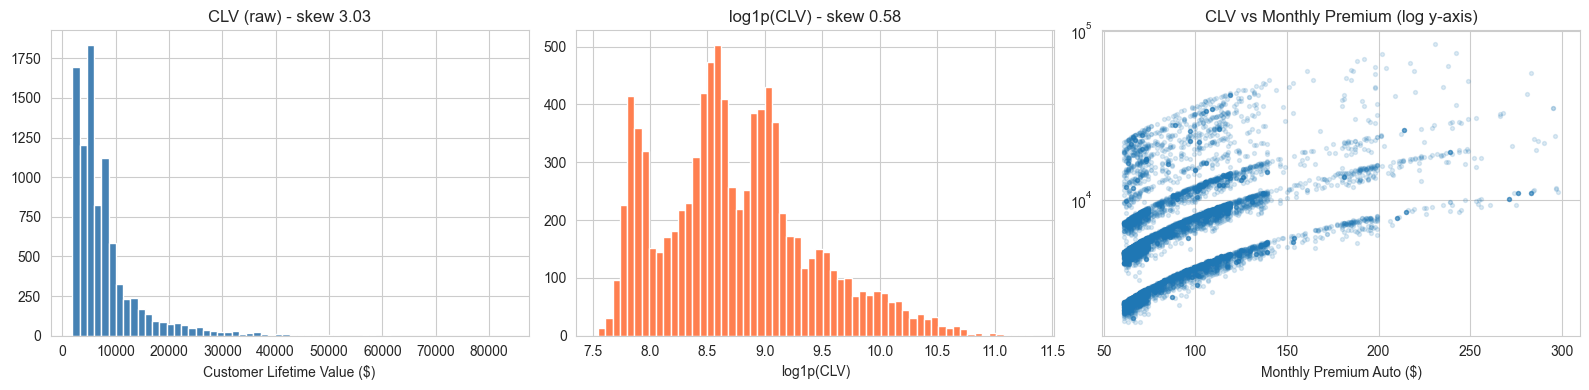

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df['clv'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title(f"CLV (raw) - skew {df['clv'].skew():.2f}")
axes[0].set_xlabel('Customer Lifetime Value ($)')

axes[1].hist(df['log_clv'], bins=60, color='coral', edgecolor='white')
axes[1].set_title(f"log1p(CLV) - skew {df['log_clv'].skew():.2f}")
axes[1].set_xlabel('log1p(CLV)')

axes[2].scatter(df['Monthly_Premium_Auto'], df['clv'], alpha=0.15, s=8)
axes[2].set_yscale('log')
axes[2].set_title('CLV vs Monthly Premium (log y-axis)')
axes[2].set_xlabel('Monthly Premium Auto ($)')

plt.tight_layout()
plt.show()

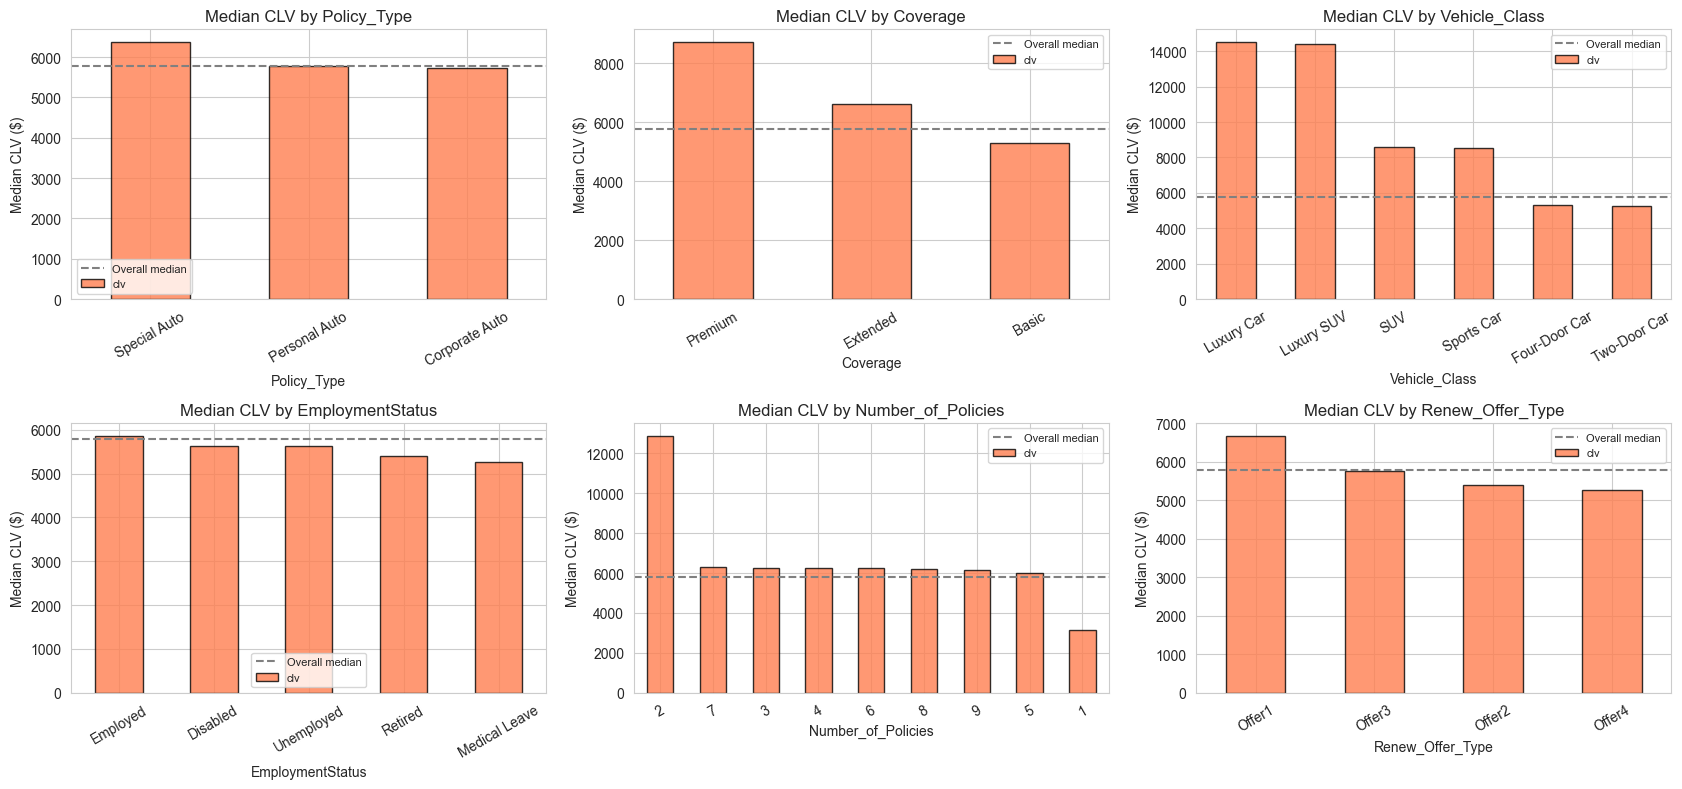

In [9]:
# Median CLV by key categoricals
cat_eda = ['Policy_Type', 'Coverage', 'Vehicle_Class', 'EmploymentStatus', 'Number_of_Policies', 'Renew_Offer_Type']
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.ravel(), cat_eda):
    med = df.groupby(col)['clv'].median().sort_values(ascending=False)
    med.plot.bar(ax=ax, color='coral', edgecolor='black', alpha=0.8)
    ax.axhline(df['clv'].median(), color='grey', linestyle='--', label='Overall median')
    ax.set_title(f'Median CLV by {col}')
    ax.set_ylabel('Median CLV ($)')
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [10]:
# Top correlations with log(CLV)
numeric_cols = df.select_dtypes(include='number').columns.drop(['clv', 'log_clv', 'Customer_Lifetime_Value'])
corr = df[numeric_cols].corrwith(df['log_clv']).sort_values(key=abs, ascending=False)
print("Top correlations with log(CLV):\n")
print(corr.head(15).to_string())

Top correlations with log(CLV):

Monthly_Premium_Auto         0.443665
premium_x_policies           0.344786
is_luxury_vehicle            0.255621
Total_Claim_Amount           0.245375
premium_x_inception          0.238203
coverage_ord                 0.223760
Number_of_Policies           0.195649
premium_per_policy          -0.193148
claim_per_policy            -0.143829
income_per_premium          -0.101297
is_multi_policy              0.075606
income_zero                 -0.045769
Number_of_Open_Complaints   -0.045370
Income                       0.041947
has_complaints              -0.023515


In [11]:
# Group means: what separates high-CLV from low-CLV customers?
q = pd.qcut(df['clv'], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
print(df.groupby(q, observed=True)[['Monthly_Premium_Auto', 'Number_of_Policies', 'Total_Claim_Amount', 'Income', 'coverage_ord']].mean().round(2).to_string())

              Monthly_Premium_Auto  Number_of_Policies  Total_Claim_Amount    Income  coverage_ord
clv                                                                                               
Q1 (lowest)                  76.45                1.01              359.78  36118.89          0.34
Q2                           84.90                3.88              390.44  38003.59          0.30
Q3                           94.72                4.14              438.85  38173.94          0.55
Q4 (highest)                116.82                2.84              547.29  38333.54          0.74


---
# 5. Modeling Setup (shared across all phases)

In [12]:
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, cross_val_predict, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error, r2_score
)

# Target: model log1p(CLV); keep dollars around for reporting
y = df['log_clv']
y_dollar = df['clv']

# Feature groups
numeric_features = [
    'Income', 'Monthly_Premium_Auto', 'Months_Since_Last_Claim',
    'Months_Since_Policy_Inception', 'Number_of_Open_Complaints',
    'Number_of_Policies', 'Total_Claim_Amount',
    'coverage_ord', 'education_ord', 'vehicle_size_ord', 'policy_level',
    'premium_x_policies', 'premium_per_policy', 'premium_x_inception',
    'claim_to_premium', 'claim_per_policy', 'claim_recency_ratio',
    'income_per_premium', 'eff_day'
]

binary_features = [
    'Response', 'Gender', 'income_zero', 'has_complaints',
    'is_luxury_vehicle', 'is_multi_policy'
]

categorical_features = [
    'State', 'EmploymentStatus', 'Location_Code', 'Marital_Status',
    'Policy_Type', 'Renew_Offer_Type', 'Sales_Channel', 'Vehicle_Class'
]

all_features = numeric_features + binary_features + categorical_features
X = df[all_features]

# Plain random split (no stratification for a continuous target)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train log-CLV mean/std: {y_train.mean():.3f} / {y_train.std():.3f}  |  Test: {y_test.mean():.3f} / {y_test.std():.3f}")

Train: (7307, 33)  |  Test: (1827, 33)
Train log-CLV mean/std: 8.754 / 0.650  |  Test: 8.726 / 0.666


In [13]:
# --- Preprocessors ---

# Linear models: scale numerics, OHE categoricals (drop first to avoid collinearity)
linear_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('bin', 'passthrough', binary_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
        ]), categorical_features)
    ]
)

# Tree models: no scaling needed, OHE all levels
tree_preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_features),
        ('bin', 'passthrough', binary_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features)
    ]
)

X_train_lin = linear_preprocessor.fit_transform(X_train)
X_test_lin = linear_preprocessor.transform(X_test)

X_train_tree = tree_preprocessor.fit_transform(X_train)
X_test_tree = tree_preprocessor.transform(X_test)

print(f"Linear shape: {X_train_lin.shape}  |  Tree shape: {X_train_tree.shape}")

Linear shape: (7307, 50)  |  Tree shape: (7307, 58)


In [14]:
# --- Shared utilities ---

def evaluate(name, y_true_log, pred_log):
    """Metrics on the log scale (what we optimise) and on the dollar scale (what the business sees)."""
    true_d, pred_d = np.expm1(y_true_log), np.expm1(pred_log)
    return {
        'Model': name,
        'RMSE (log)': root_mean_squared_error(y_true_log, pred_log),
        'MAE (log)': mean_absolute_error(y_true_log, pred_log),
        'R2 (log)': r2_score(y_true_log, pred_log),
        'MAE ($)': mean_absolute_error(true_d, pred_d),
        'R2 ($)': r2_score(true_d, pred_d),
    }

from joblib import Parallel, delayed

def manual_cv_rmse(model_fn, X, y, cv):
    """Manual CV for models incompatible with cross_val_score (e.g. CatBoost); folds run in parallel."""
    def fit_score(train_idx, val_idx):
        model = model_fn()
        model.fit(X[train_idx], y.iloc[train_idx])
        return root_mean_squared_error(y.iloc[val_idx], model.predict(X[val_idx]))

    scores = Parallel(n_jobs=5)(
        delayed(fit_score)(tr, va) for tr, va in cv.split(X, y)
    )
    return np.mean(scores)

def cv_rmse(model, X, y):
    return -cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1).mean()

all_results = []  # collects metrics across all phases
cv_results = {}   # model name -> CV RMSE on the training set

---
# 6. Phase 1 — Sklearn Baselines (no tuning)

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

tic('Phase 1 — Baselines')

phase1_models = [
    ('P1: Dummy (mean)', DummyRegressor(strategy='mean'), X_train_lin, X_test_lin),
    ('P1: Linear Regression', LinearRegression(), X_train_lin, X_test_lin),
    ('P1: Random Forest', RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), X_train_tree, X_test_tree),
    ('P1: Gradient Boosting', GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE), X_train_tree, X_test_tree),
]

phase1_trained = {}
for name, model, X_tr, X_te in phase1_models:
    cv_results[name] = cv_rmse(model, X_tr, y_train)      # 5-fold CV on the training set
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    all_results.append(evaluate(name, y_test, pred))
    phase1_trained[name] = {'model': model, 'pred': pred}

toc('Phase 1 — Baselines')

[TIMER] Starting: Phase 1 — Baselines


[TIMER] Phase 1 — Baselines: 0m 9.7s


9.677863707998767

In [16]:
p1 = pd.DataFrame([r for r in all_results if r['Model'].startswith('P1')])
p1['CV RMSE (log)'] = p1['Model'].map(cv_results)
p1

,Model,RMSE (log),MAE (log),R2 (log),MAE ($),R2 ($),CV RMSE (log)
0,P1: Dummy (mean),0.665919,0.533267,-0.001804,4176.548108,-0.049426,0.649592
1,P1: Linear Regression,0.283932,0.198375,0.817875,2201.163355,0.362284,0.289513
2,P1: Random Forest,0.200689,0.092540,0.909011,1394.649644,0.675868,0.196613
3,P1: Gradient Boosting,0.207777,0.108899,0.902471,1571.682558,0.655303,0.204492


**Phase 1 observations:**
- The mean-predicting dummy sets the floor (R² ≈ 0 on the log scale). Everything else is measured against it.
- **The linear/tree gap is large** (R² log 0.82 vs 0.90-0.91, RMSE 0.28 vs 0.20). Unlike churn, where Logistic Regression was already competitive, CLV has strong non-linear structure and interactions that a linear model cannot express, even with engineered features.
- Untuned Random Forest and Gradient Boosting already sit near the best score we will see in any later phase. Most of the achievable accuracy is available at the baseline stage.
- Dollar-scale R² is much lower than log-scale R² (0.36-0.68 vs 0.82-0.91): the dollar metric is dominated by a handful of very high CLV customers (the max is ~$83k against a median of ~$5.8k).
- Cross-validated RMSE on the training set tracks the test RMSE closely, so the single 80/20 split is not misleading us.

---
# 7. Phase 2 — Sklearn with Tuning

In [17]:
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import uniform, randint, loguniform

tic('Phase 2 — Tuned Sklearn')

[TIMER] Starting: Phase 2 — Tuned Sklearn


In [18]:
# ElasticNet — tuned (regularised linear model)
tic('P2: ElasticNet tuning')
en_search = RandomizedSearchCV(
    ElasticNet(max_iter=10000, random_state=RANDOM_STATE),
    {'alpha': loguniform(1e-4, 1), 'l1_ratio': uniform(0.05, 0.95)},
    n_iter=40, scoring='neg_root_mean_squared_error', cv=cv, random_state=RANDOM_STATE, n_jobs=-1
)
en_search.fit(X_train_lin, y_train)
print(f"Best CV RMSE: {-en_search.best_score_:.4f}, params: {en_search.best_params_}")
toc('P2: ElasticNet tuning')

[TIMER] Starting: P2: ElasticNet tuning


Best CV RMSE: 0.2893, params: {'alpha': np.float64(0.000366181922039243), 'l1_ratio': np.float64(0.8120871317163377)}
[TIMER] P2: ElasticNet tuning: 0m 0.8s


0.8208715409855358

In [19]:
# Random Forest — tuned
tic('P2: RF tuning')
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    {
        'n_estimators': randint(100, 400), 'max_depth': [5, 10, 15, 20, None],
        'min_samples_split': randint(2, 20), 'min_samples_leaf': randint(1, 10),
        'max_features': ['sqrt', 'log2', 0.3, 0.5],
    },
    n_iter=40, scoring='neg_root_mean_squared_error', cv=cv, random_state=RANDOM_STATE, n_jobs=-1
)
rf_search.fit(X_train_tree, y_train)
print(f"Best CV RMSE: {-rf_search.best_score_:.4f}, params: {rf_search.best_params_}")
toc('P2: RF tuning')

[TIMER] Starting: P2: RF tuning


Best CV RMSE: 0.1940, params: {'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 330}
[TIMER] P2: RF tuning: 0m 48.3s


48.32411987497471

In [20]:
# HistGradientBoosting — tuned
tic('P2: HGB tuning')
hgb_search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    {
        'learning_rate': loguniform(0.01, 0.3), 'max_depth': randint(3, 10),
        'min_samples_leaf': randint(10, 50), 'max_iter': randint(100, 500),
        'l2_regularization': loguniform(1e-4, 10),
    },
    n_iter=60, scoring='neg_root_mean_squared_error', cv=cv, random_state=RANDOM_STATE, n_jobs=-1
)
hgb_search.fit(X_train_tree, y_train)
print(f"Best CV RMSE: {-hgb_search.best_score_:.4f}, params: {hgb_search.best_params_}")
toc('P2: HGB tuning')

[TIMER] Starting: P2: HGB tuning


Best CV RMSE: 0.1976, params: {'l2_regularization': np.float64(0.0003974905761171869), 'learning_rate': np.float64(0.0315281541750961), 'max_depth': 9, 'max_iter': 414, 'min_samples_leaf': 41}
[TIMER] P2: HGB tuning: 0m 36.3s


36.276424666983075

In [21]:
# Evaluate Phase 2 tuned models
p2_models = [
    ('P2: ElasticNet (tuned)', en_search.best_estimator_, X_train_lin, X_test_lin, -en_search.best_score_),
    ('P2: RF (tuned)', rf_search.best_estimator_, X_train_tree, X_test_tree, -rf_search.best_score_),
    ('P2: HGB (tuned)', hgb_search.best_estimator_, X_train_tree, X_test_tree, -hgb_search.best_score_),
]

phase2_trained = {}
for name, model, X_tr, X_te, cv_score in p2_models:
    cv_results[name] = cv_score
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    all_results.append(evaluate(name, y_test, pred))
    phase2_trained[name] = {'model': model, 'pred': pred}

toc('Phase 2 — Tuned Sklearn')
p2 = pd.DataFrame([r for r in all_results if r['Model'].startswith('P2')])
p2['CV RMSE (log)'] = p2['Model'].map(cv_results)
p2

[TIMER] Phase 2 — Tuned Sklearn: 1m 32.5s


,Model,RMSE (log),MAE (log),R2 (log),MAE ($),R2 ($),CV RMSE (log)
0,P2: ElasticNet (tuned),0.284205,0.197941,0.817524,2188.847378,0.371742,0.289282
1,P2: RF (tuned),0.197541,0.093487,0.911843,1405.779414,0.679740,0.193954
2,P2: HGB (tuned),0.198845,0.097420,0.910675,1435.672933,0.679989,0.197573


**Phase 2 observations:**
- **Tuning barely moves the needle.** Tuned Random Forest improves test RMSE (log) from 0.201 to 0.198 and HGB lands at 0.199, versus the untuned Random Forest at 0.201. Those gaps are well inside what a different random seed would produce.
- ElasticNet stays at RMSE 0.284 with and without tuning: the linear model's limit is structural, not a hyperparameter problem.
- There is no equivalent of churn's `class_weight='balanced'` step here; regression has no single cheap change that delivers a big jump, so the big jump already happened in Phase 1 (trees vs linear).

---
# 8. Phase 3 — XGBoost / LightGBM / CatBoost + Optuna

In [22]:
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

tic('Phase 3 — Advanced Models')

[TIMER] Starting: Phase 3 — Advanced Models


In [23]:
# --- XGBoost + Optuna ---
tic('P3: XGBoost Optuna')

def xgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'gamma': trial.suggest_float('gamma', 0, 5),
    }
    model = xgb.XGBRegressor(**params, random_state=RANDOM_STATE, tree_method='hist')
    return cv_rmse(model, X_train_tree, y_train)

study_xgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb.optimize(xgb_objective, n_trials=50, show_progress_bar=True)
print(f"Best CV RMSE: {study_xgb.best_value:.4f}")
toc('P3: XGBoost Optuna')

[TIMER] Starting: P3: XGBoost Optuna


  0%|          | 0/50 [00:00<?, ?it/s]

Best CV RMSE: 0.1972
[TIMER] P3: XGBoost Optuna: 0m 19.7s


19.684679792029783

In [24]:
# --- LightGBM + Optuna ---
tic('P3: LightGBM Optuna')

def lgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
    }
    model = lgb.LGBMRegressor(**params, random_state=RANDOM_STATE, verbose=-1, n_jobs=1)
    return cv_rmse(model, X_train_tree, y_train)

study_lgb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgb.optimize(lgb_objective, n_trials=50, show_progress_bar=True)
print(f"Best CV RMSE: {study_lgb.best_value:.4f}")
toc('P3: LightGBM Optuna')

[TIMER] Starting: P3: LightGBM Optuna


  0%|          | 0/50 [00:00<?, ?it/s]

Best CV RMSE: 0.1956
[TIMER] P3: LightGBM Optuna: 0m 33.9s


33.87600550003117

In [25]:
# --- CatBoost + Optuna ---
tic('P3: CatBoost Optuna')

def cb_objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 600),
        'depth': trial.suggest_int('depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10, log=True),
        'border_count': trial.suggest_int('border_count', 32, 255),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0, 5),
        'random_strength': trial.suggest_float('random_strength', 0, 5),
    }
    def make_model():
        return CatBoostRegressor(**params, random_seed=RANDOM_STATE, verbose=0, thread_count=2)
    return manual_cv_rmse(make_model, X_train_tree, y_train, cv)

study_cb = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_cb.optimize(cb_objective, n_trials=30, show_progress_bar=True)
print(f"Best CV RMSE: {study_cb.best_value:.4f}")
toc('P3: CatBoost Optuna')

[TIMER] Starting: P3: CatBoost Optuna


  0%|          | 0/30 [00:00<?, ?it/s]

Best CV RMSE: 0.1935
[TIMER] P3: CatBoost Optuna: 0m 37.3s


37.3169637080282

In [26]:
# Train and evaluate Phase 3 models
tic('P3: Final fits')

xgb_best = xgb.XGBRegressor(**study_xgb.best_params, random_state=RANDOM_STATE, tree_method='hist')
xgb_best.fit(X_train_tree, y_train)
pred_xgb = xgb_best.predict(X_test_tree)
all_results.append(evaluate('P3: XGBoost (tuned)', y_test, pred_xgb))

lgb_best = lgb.LGBMRegressor(**study_lgb.best_params, subsample_freq=1, random_state=RANDOM_STATE, verbose=-1)
lgb_best.fit(X_train_tree, y_train)
pred_lgb = lgb_best.predict(X_test_tree)
all_results.append(evaluate('P3: LightGBM (tuned)', y_test, pred_lgb))

cb_best = CatBoostRegressor(**study_cb.best_params, random_seed=RANDOM_STATE, verbose=0)
cb_best.fit(X_train_tree, y_train)
pred_cb = cb_best.predict(X_test_tree)
all_results.append(evaluate('P3: CatBoost (tuned)', y_test, pred_cb))

cv_results['P3: XGBoost (tuned)'] = study_xgb.best_value
cv_results['P3: LightGBM (tuned)'] = study_lgb.best_value
cv_results['P3: CatBoost (tuned)'] = study_cb.best_value

toc('P3: Final fits')

[TIMER] Starting: P3: Final fits


[TIMER] P3: Final fits: 0m 9.5s


9.522399124980439

In [27]:
# Voting ensemble: plain average of predictions
pred_en = en_search.best_estimator_.predict(X_test_lin)
pred_vote = (pred_en + pred_xgb + pred_lgb + pred_cb) / 4.0
all_results.append(evaluate('P3: Voting Ensemble', y_test, pred_vote))

# Stacking ensemble
tic('P3: Stacking')
oof_en = cross_val_predict(en_search.best_estimator_, X_train_lin, y_train, cv=cv)
oof_xgb = cross_val_predict(xgb_best, X_train_tree, y_train, cv=cv)
oof_lgb = cross_val_predict(lgb_best, X_train_tree, y_train, cv=cv)

oof_cb = np.zeros(len(y_train))
for train_idx, val_idx in cv.split(X_train_tree, y_train):
    cb_fold = CatBoostRegressor(**study_cb.best_params, random_seed=RANDOM_STATE, verbose=0)
    cb_fold.fit(X_train_tree[train_idx], y_train.iloc[train_idx])
    oof_cb[val_idx] = cb_fold.predict(X_train_tree[val_idx])

meta_train = np.column_stack([oof_en, oof_xgb, oof_lgb, oof_cb])
meta_test = np.column_stack([pred_en, pred_xgb, pred_lgb, pred_cb])

meta_lr = LinearRegression(positive=True)   # non-negative weights keep the blend interpretable
meta_lr.fit(meta_train, y_train)
pred_stack = meta_lr.predict(meta_test)
all_results.append(evaluate('P3: Stacking', y_test, pred_stack))
print(f"Meta-learner weights: {dict(zip(['EN', 'XGB', 'LGB', 'CB'], meta_lr.coef_.round(3)))}  intercept={meta_lr.intercept_:.3f}")

cv_results['P3: Stacking'] = root_mean_squared_error(y_train, meta_lr.predict(meta_train))   # OOF-based
toc('P3: Stacking')
toc('Phase 3 — Advanced Models')

[TIMER] Starting: P3: Stacking


Meta-learner weights: {'EN': np.float64(0.023), 'XGB': np.float64(0.0), 'LGB': np.float64(0.325), 'CB': np.float64(0.66)}  intercept=-0.069
[TIMER] P3: Stacking: 0m 44.8s
[TIMER] Phase 3 — Advanced Models: 2m 25.3s


145.25250712496927

In [28]:
p3 = pd.DataFrame([r for r in all_results if r['Model'].startswith('P3')])
p3['CV RMSE (log)'] = p3['Model'].map(cv_results)
p3

,Model,RMSE (log),MAE (log),R2 (log),MAE ($),R2 ($),CV RMSE (log)
0,P3: XGBoost (tuned),0.200756,0.098234,0.908950,1463.836092,0.675985,0.197216
1,P3: LightGBM (tuned),0.199529,0.093056,0.910060,1414.017150,0.671294,0.195576
2,P3: CatBoost (tuned),0.198203,0.098742,0.911251,1424.984093,0.686880,0.193507
3,P3: Voting Ensemble,0.202707,0.112352,0.907172,1542.763972,0.676636,NaN
4,P3: Stacking,0.197042,0.095531,0.912288,1415.284600,0.686227,0.192758


**Phase 3 observations:**
- XGBoost, LightGBM and CatBoost land at test RMSE (log) 0.198-0.201: indistinguishable from tuned Random Forest (0.198) and HGB (0.199).
- CatBoost has the best cross-validated RMSE among single models (0.1935) and the best dollar R² (0.687), but the margins over the other boosters are in the third decimal place.
- **Stacking** gives the lowest test RMSE (0.1970) by leaning on CatBoost (weight ~0.66) and LightGBM (~0.33); it gives XGBoost zero weight and ElasticNet almost none. Note its "CV RMSE" is computed on the out-of-fold predictions the meta-learner was fit to, so it is slightly optimistic.
- **Voting is the worst ensemble** (0.2027) because it gives the weak ElasticNet an equal 25% vote. Averaging only helps when the members are comparably good.

---
# 9. Full Comparison Across All Phases

In [29]:
results_df = pd.DataFrame(all_results)
results_df['CV RMSE (log)'] = results_df['Model'].map(cv_results)
results_df.style.format(precision=4).highlight_min(
    subset=['RMSE (log)', 'MAE (log)', 'MAE ($)', 'CV RMSE (log)'], color='lightgreen'
).highlight_max(
    subset=['R2 (log)', 'R2 ($)'], color='lightgreen'
)

,Model,RMSE (log),MAE (log),R2 (log),MAE ($),R2 ($),CV RMSE (log)
0,P1: Dummy (mean),0.6659,0.5333,-0.0018,4176.5481,-0.0494,0.6496
1,P1: Linear Regression,0.2839,0.1984,0.8179,2201.1634,0.3623,0.2895
2,P1: Random Forest,0.2007,0.0925,0.9090,1394.6496,0.6759,0.1966
3,P1: Gradient Boosting,0.2078,0.1089,0.9025,1571.6826,0.6553,0.2045
4,P2: ElasticNet (tuned),0.2842,0.1979,0.8175,2188.8474,0.3717,0.2893
5,P2: RF (tuned),0.1975,0.0935,0.9118,1405.7794,0.6797,0.1940
6,P2: HGB (tuned),0.1988,0.0974,0.9107,1435.6729,0.6800,0.1976
7,P3: XGBoost (tuned),0.2008,0.0982,0.9090,1463.8361,0.6760,0.1972
8,P3: LightGBM (tuned),0.1995,0.0931,0.9101,1414.0172,0.6713,0.1956
9,P3: CatBoost (tuned),0.1982,0.0987,0.9113,1424.9841,0.6869,0.1935


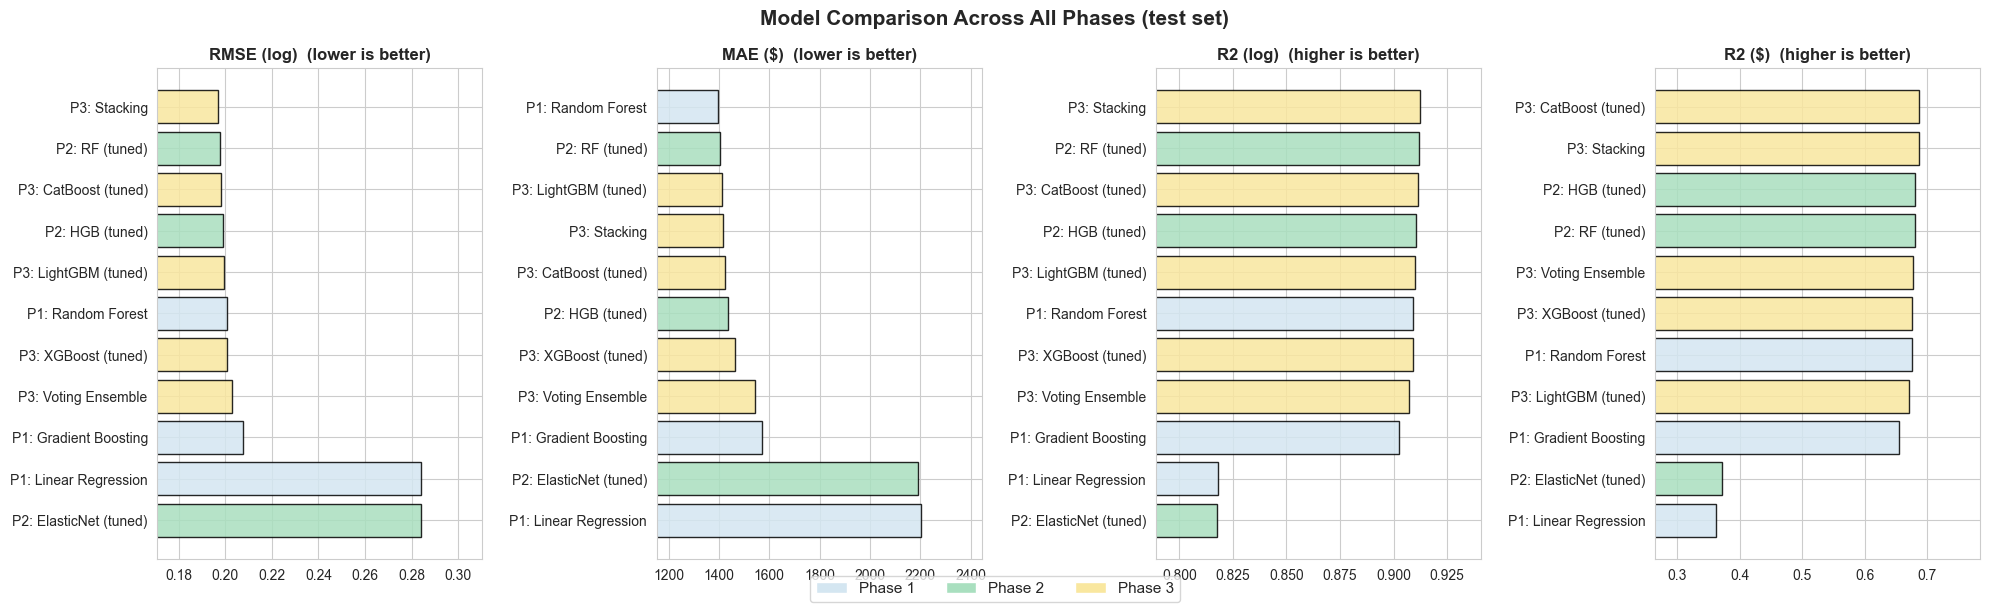

In [30]:
# Visual comparison (drop the dummy so the interesting differences are visible)
plot_df = results_df[~results_df['Model'].str.contains('Dummy')]
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

panels = [('RMSE (log)', True), ('MAE ($)', True), ('R2 (log)', False), ('R2 ($)', False)]
for ax, (metric, lower_better) in zip(axes, panels):
    data = plot_df.sort_values(metric, ascending=not lower_better)
    colors = ['#d4e6f1' if m.startswith('P1') else '#a9dfbf' if m.startswith('P2') else '#f9e79f' for m in data['Model']]
    ax.barh(data['Model'], data[metric], color=colors, edgecolor='black', alpha=0.85)
    ax.set_title(metric + ('  (lower is better)' if lower_better else '  (higher is better)'), fontsize=12, fontweight='bold')
    lo, hi = data[metric].min(), data[metric].max()
    pad = (hi - lo) * 0.3 + 1e-9
    ax.set_xlim(lo - pad, hi + pad)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#d4e6f1', label='Phase 1'), Patch(facecolor='#a9dfbf', label='Phase 2'), Patch(facecolor='#f9e79f', label='Phase 3')]
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=11, bbox_to_anchor=(0.5, -0.02))

plt.suptitle('Model Comparison Across All Phases (test set)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

---
# 10. Target Transformation — Does the Log Help?

In [31]:
# Same tuned HGB, trained on raw dollars vs log-dollars; judged on dollars (R2 and MAE)
y_train_d, y_test_d = np.expm1(y_train), np.expm1(y_test)
hgb_params = hgb_search.best_params_

hgb_raw = HistGradientBoostingRegressor(**hgb_params, random_state=RANDOM_STATE).fit(X_train_tree, y_train_d)
pred_raw = hgb_raw.predict(X_test_tree)

pred_log_d = np.expm1(phase2_trained['P2: HGB (tuned)']['pred'])

# Smearing correction: expm1(pred) estimates the median; multiply by the mean residual factor to estimate the mean
resid_train = y_train - hgb_search.best_estimator_.predict(X_train_tree)
smear = np.mean(np.exp(resid_train))
pred_log_smeared = (pred_log_d + 1) * smear - 1

target_cmp = pd.DataFrame({
    'Setup': ['Raw target', 'log1p target', 'log1p target + smearing'],
    'MAE ($)': [mean_absolute_error(y_test_d, p) for p in (pred_raw, pred_log_d, pred_log_smeared)],
    'RMSE ($)': [root_mean_squared_error(y_test_d, p) for p in (pred_raw, pred_log_d, pred_log_smeared)],
    'R2 ($)': [r2_score(y_test_d, p) for p in (pred_raw, pred_log_d, pred_log_smeared)],
})
print(f"Smearing factor: {smear:.3f}")
target_cmp.round(3)

Smearing factor: 1.010


,Setup,MAE ($),RMSE ($),R2 ($)
0,Raw target,1633.256,4004.502,0.689
1,log1p target,1435.673,4061.054,0.680
2,log1p target + smearing,1450.880,4044.510,0.683


**What this shows:** On the test set, the log target cuts dollar MAE by about 12% (about $1,436 vs $1,633) but is slightly *worse* on RMSE and R² in dollars (0.680 vs 0.689), because RMSE is dominated by the few very large CLVs that the raw-target model fits harder. The smearing factor is ~1.01, so the correction is nearly negligible here (it nudges RMSE down and MAE up slightly). In general: Training on the log target optimises *relative* error, which is usually the right objective for a skewed money target but is not the same thing as minimising dollar error. Back-transforming `expm1(prediction)` returns something closer to the conditional *median* than the *mean*; Duan's smearing factor corrects that bias. Which setup wins depends on whether the business cares about typical customers (median / MAE) or about total portfolio dollars (mean / RMSE). Neither dominates, and the differences are modest next to the Phase 1 gain from trees over linear models.

---
# 11. Residual Diagnostics

Best model on test RMSE (log): P3: Stacking


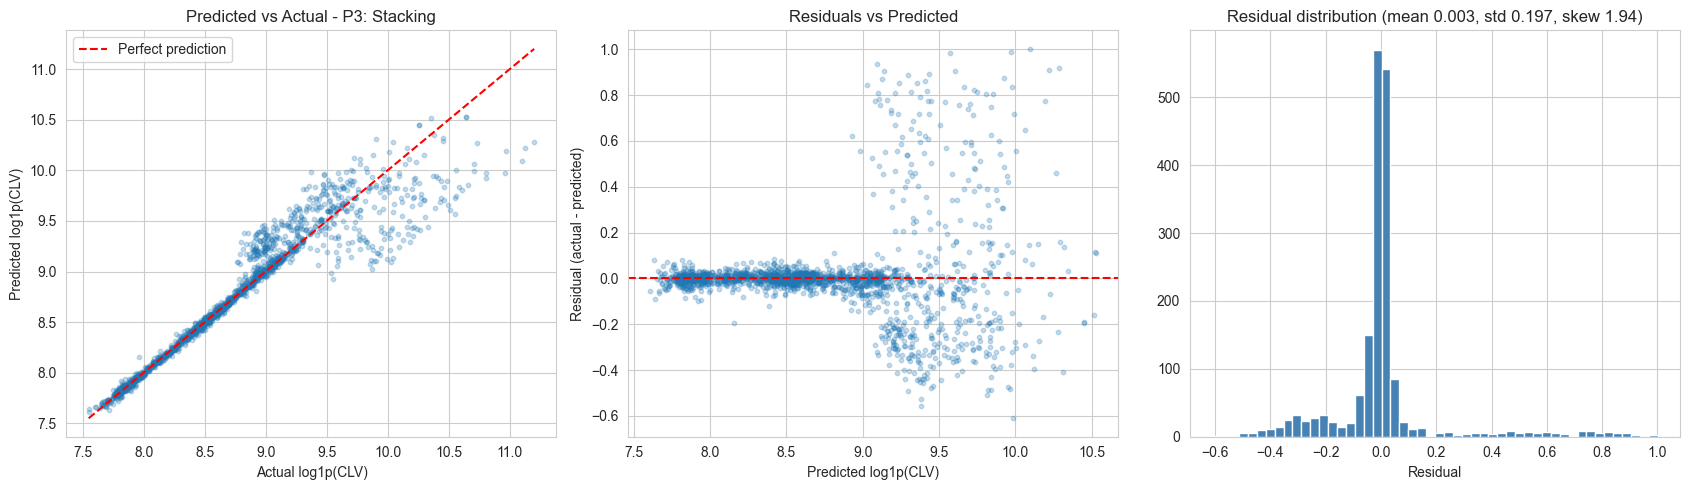

In [32]:
# Pick the best model by test RMSE (log) among the tuned/ensemble models
tuned = results_df[~results_df['Model'].str.contains('Dummy|P1')]
best_name = tuned.sort_values('RMSE (log)').iloc[0]['Model']
pred_by_name = {
    'P2: ElasticNet (tuned)': phase2_trained['P2: ElasticNet (tuned)']['pred'],
    'P2: RF (tuned)': phase2_trained['P2: RF (tuned)']['pred'],
    'P2: HGB (tuned)': phase2_trained['P2: HGB (tuned)']['pred'],
    'P3: XGBoost (tuned)': pred_xgb, 'P3: LightGBM (tuned)': pred_lgb, 'P3: CatBoost (tuned)': pred_cb,
    'P3: Voting Ensemble': pred_vote, 'P3: Stacking': pred_stack,
}
best_pred = pred_by_name[best_name]
resid = y_test.values - best_pred
print(f"Best model on test RMSE (log): {best_name}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test, best_pred, alpha=0.25, s=10)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual log1p(CLV)'); axes[0].set_ylabel('Predicted log1p(CLV)')
axes[0].set_title(f'Predicted vs Actual - {best_name}'); axes[0].legend()

axes[1].scatter(best_pred, resid, alpha=0.25, s=10)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted log1p(CLV)'); axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residuals vs Predicted')

axes[2].hist(resid, bins=50, color='steelblue', edgecolor='white')
axes[2].set_title(f'Residual distribution (mean {resid.mean():.3f}, std {resid.std():.3f}, skew {pd.Series(resid).skew():.2f})')
axes[2].set_xlabel('Residual')

plt.tight_layout()
plt.show()

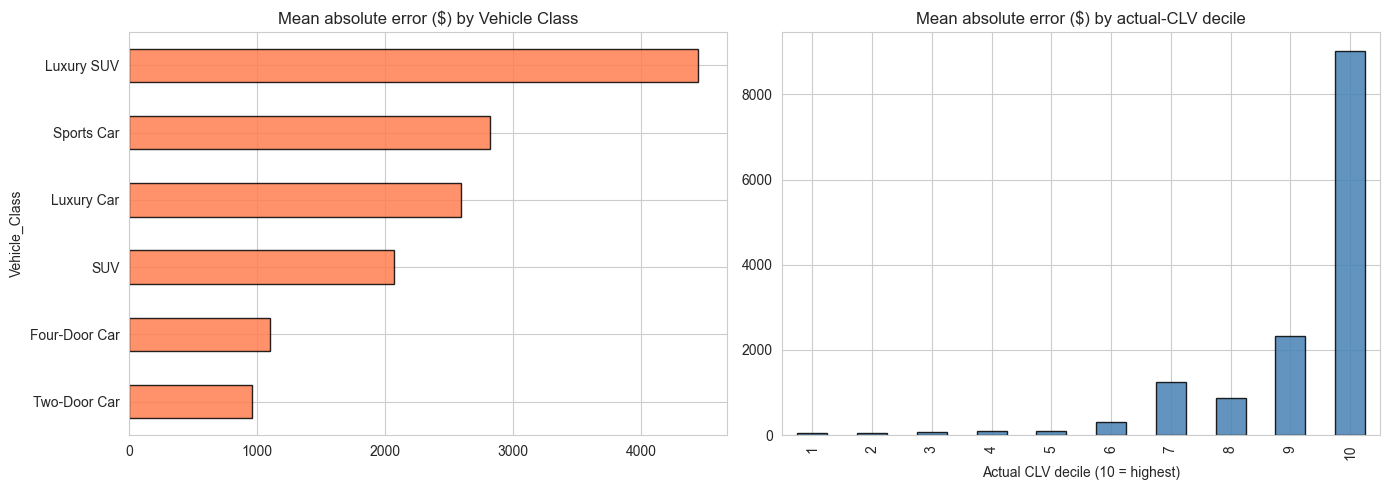

In [33]:
# Where does the model make its largest errors? Error by segment (dollar MAE)
seg = X_test.copy()
seg['abs_err_$'] = np.abs(np.expm1(y_test.values) - np.expm1(best_pred))
seg['actual_$'] = np.expm1(y_test.values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

seg.groupby('Vehicle_Class')['abs_err_$'].mean().sort_values().plot.barh(ax=axes[0], color='coral', edgecolor='black', alpha=0.85)
axes[0].set_title('Mean absolute error ($) by Vehicle Class')

decile = pd.qcut(seg['actual_$'], 10, labels=False, duplicates='drop') + 1
seg.groupby(decile)['abs_err_$'].mean().plot.bar(ax=axes[1], color='steelblue', edgecolor='black', alpha=0.85)
axes[1].set_title('Mean absolute error ($) by actual-CLV decile')
axes[1].set_xlabel('Actual CLV decile (10 = highest)')

plt.tight_layout()
plt.show()

---
# 12. What the Residuals Reveal — Hidden Structure in CLV

In [34]:
# Where does the model's error come from?
seg['sq_err_log'] = resid ** 2
by_pol = seg.groupby('Number_of_Policies').agg(
    n=('sq_err_log', 'size'),
    MAE_log=('sq_err_log', lambda s: np.mean(np.sqrt(s))),
    sq_err=('sq_err_log', 'sum'),
)
by_pol['share_of_rows'] = by_pol['n'] / by_pol['n'].sum()
by_pol['share_of_sq_error'] = by_pol['sq_err'] / by_pol['sq_err'].sum()
print(f"Median |residual| (log): {np.median(np.abs(resid)):.3f}   |   90th pct: {np.quantile(np.abs(resid), 0.9):.3f}   |   99th pct: {np.quantile(np.abs(resid), 0.99):.3f}")
print(f"Share of squared error from the worst 5% of predictions: {np.sort(resid**2)[::-1][:int(0.05*len(resid))].sum() / (resid**2).sum():.1%}")
print()
print(by_pol[['n', 'share_of_rows', 'share_of_sq_error', 'MAE_log']].round(3).to_string())

Median |residual| (log): 0.023   |   90th pct: 0.320   |   99th pct: 0.822
Share of squared error from the worst 5% of predictions: 64.0%

                      n  share_of_rows  share_of_sq_error  MAE_log
Number_of_Policies                                                
1                   680          0.372              0.007    0.019
2                   456          0.250              0.983    0.320
3                   234          0.128              0.005    0.028
4                    76          0.042              0.001    0.021
5                    82          0.045              0.001    0.018
6                    71          0.039              0.001    0.023
7                    76          0.042              0.002    0.024
8                    76          0.042              0.001    0.019
9                    76          0.042              0.001    0.020


                     count   min    25%    50%    75%    max
Number_of_Policies                                          
1                   3251.0  26.1   36.9   39.2   39.9   41.0
2                   2294.0  84.7  115.9  120.3  229.1  365.8
3                   1168.0  48.4   74.1   78.6   80.0   81.8
4                    409.0  62.4   73.2   78.1   79.8   81.8
5                    407.0  60.0   72.8   78.2   80.0   81.7
6                    372.0  57.9   73.6   78.8   80.0   81.8
7                    433.0  52.6   73.0   78.3   79.7   81.9
8                    384.0  60.4   74.9   78.6   79.7   81.6
9                    416.0  57.9   73.7   78.1   80.0   81.6


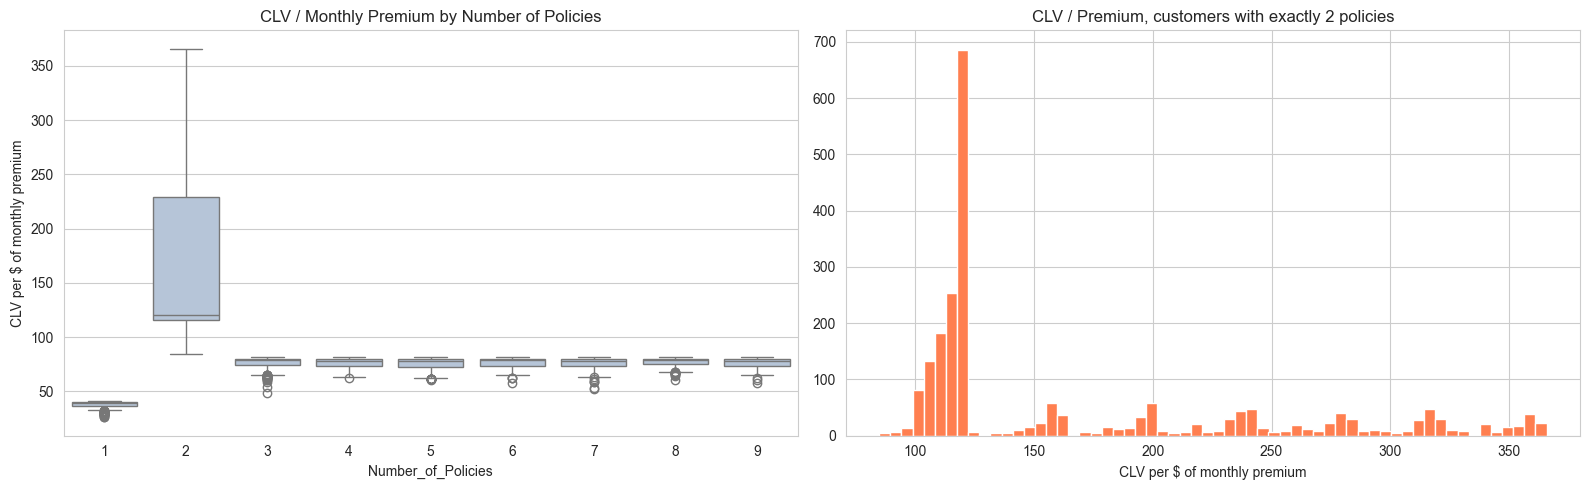

In [35]:
# CLV is almost "premium x a constant" - but the constant depends on the number of policies
df['clv_per_premium'] = df['clv'] / df['Monthly_Premium_Auto']
print(df.groupby('Number_of_Policies')['clv_per_premium'].describe()[['count', 'min', '25%', '50%', '75%', 'max']].round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x='Number_of_Policies', y='clv_per_premium', ax=axes[0], color='lightsteelblue')
axes[0].set_title('CLV / Monthly Premium by Number of Policies')
axes[0].set_ylabel('CLV per $ of monthly premium')

two = df.loc[df['Number_of_Policies'] == 2, 'clv_per_premium']
axes[1].hist(two, bins=60, color='coral', edgecolor='white')
axes[1].set_title('CLV / Premium, customers with exactly 2 policies')
axes[1].set_xlabel('CLV per $ of monthly premium')
plt.tight_layout()
plt.show()

In [36]:
# Can ANY feature explain the spread within the 2-policy group? Try to predict the (log) ratio there.
mask = (df['Number_of_Policies'] == 2).values
Xp = tree_preprocessor.transform(X)[mask]
yp = np.log(df.loc[mask, 'clv_per_premium']).values
r2_two = cross_val_score(HistGradientBoostingRegressor(random_state=RANDOM_STATE), Xp, yp, cv=cv, scoring='r2').mean()
print(f"CV R2 predicting log(CLV/premium) within 2-policy customers: {r2_two:.3f}  (n={mask.sum()})")

CV R2 predicting log(CLV/premium) within 2-policy customers: 0.023  (n=2294)


**What this shows:**
- The typical error is tiny (median |residual| about 0.023 on the log scale, i.e. about 2%), but the error distribution has a very heavy tail: the worst 5% of predictions produce about 64% of the squared error.
- **Customers with exactly two policies are 25% of the test rows but 98% of the squared error.** For 1 policy, CLV is roughly 39 x monthly premium; for 3-9 policies it is roughly 78 x premium, both with a spread of only a few percent. For 2 policies the multiplier is bimodal: a main cluster near 120 and a long tail up to ~365.
- Gradient boosting cannot predict where within that 2-policy spread a customer falls (CV R² = 0.02): none of the 33 features carries that information. This is the real **performance ceiling**, and it is a *data* ceiling, exactly as in the churn study.
- Such clean multiplicative structure is unusual for real insurance data and suggests the dataset is synthetic or simulated. That is worth remembering before generalising any of these numbers to a production book of business.

---
# 13. Prediction Intervals

In [37]:
# Quantile LightGBM: 5th / 95th percentile -> nominal 90% prediction interval
tic('Prediction intervals')
lgb_q_params = dict(study_lgb.best_params, subsample_freq=1)
q_lo = lgb.LGBMRegressor(objective='quantile', alpha=0.05, **lgb_q_params, random_state=RANDOM_STATE, verbose=-1).fit(X_train_tree, y_train)
q_hi = lgb.LGBMRegressor(objective='quantile', alpha=0.95, **lgb_q_params, random_state=RANDOM_STATE, verbose=-1).fit(X_train_tree, y_train)
lo, hi = q_lo.predict(X_test_tree), q_hi.predict(X_test_tree)
lo, hi = np.minimum(lo, hi), np.maximum(lo, hi)

cover_q = np.mean((y_test.values >= lo) & (y_test.values <= hi))
print(f"Quantile GBM:  nominal 90%  ->  empirical coverage {cover_q:.1%}, mean width {np.mean(hi - lo):.3f} (log units)")

# Split-conformal alternative: use cross-validated residuals of the best model to size a symmetric band
oof_best = cross_val_predict(lgb_best, X_train_tree, y_train, cv=cv)
q90 = np.quantile(np.abs(y_train.values - oof_best), 0.90)
cover_c = np.mean(np.abs(y_test.values - pred_lgb) <= q90)
print(f"Conformal (CV residuals): nominal 90%  ->  empirical coverage {cover_c:.1%}, width {2 * q90:.3f} (log units)")
toc('Prediction intervals')

[TIMER] Starting: Prediction intervals


Quantile GBM:  nominal 90%  ->  empirical coverage 87.9%, mean width 0.496 (log units)


Conformal (CV residuals): nominal 90%  ->  empirical coverage 90.1%, width 0.649 (log units)
[TIMER] Prediction intervals: 0m 46.3s


46.29217400000198

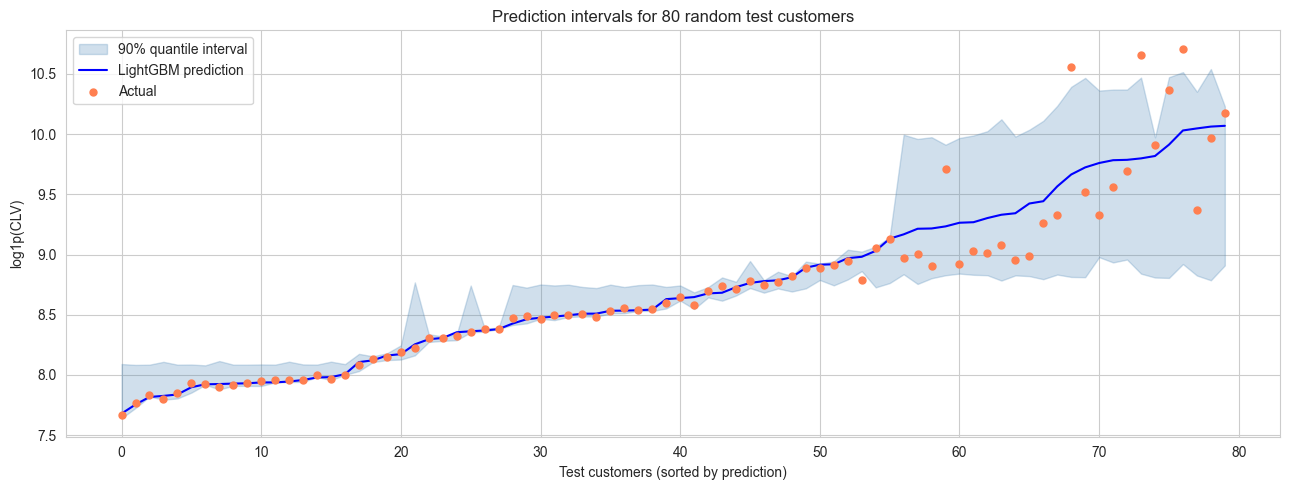

In [38]:
# Show intervals for a random sample of test customers, sorted by prediction
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(y_test), 80, replace=False)
idx = idx[np.argsort(pred_lgb[idx])]

fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(range(len(idx)), lo[idx], hi[idx], alpha=0.25, color='steelblue', label='90% quantile interval')
ax.plot(range(len(idx)), pred_lgb[idx], 'b-', label='LightGBM prediction')
ax.scatter(range(len(idx)), y_test.values[idx], color='coral', s=25, zorder=3, label='Actual')
ax.set_xlabel('Test customers (sorted by prediction)')
ax.set_ylabel('log1p(CLV)')
ax.set_title('Prediction intervals for 80 random test customers')
ax.legend()
plt.tight_layout()
plt.show()

**What this shows:** The quantile-GBM interval is a bit too narrow (about 88% empirical coverage for a nominal 90%) but its width is *adaptive*: the model is nearly exact for most customers and wide only where it is uncertain. The conformal band is correctly calibrated (about 90%) but uses one fixed width for everyone, so it is about 30% wider on average and wasteful for the near-deterministic customers. For regression, this is the counterpart of the churn study's calibration question: can you trust the model's stated uncertainty?

---
# 14. SHAP — Feature Importance

In [39]:
import shap

tic('SHAP')

cat_names_tree = tree_preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_features)
tree_feature_names = list(numeric_features) + list(binary_features) + list(cat_names_tree)

explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test_tree)
X_test_tree_df = pd.DataFrame(X_test_tree, columns=tree_feature_names)

toc('SHAP')

[TIMER] Starting: SHAP


[TIMER] SHAP: 0m 0.3s


0.3050655419938266

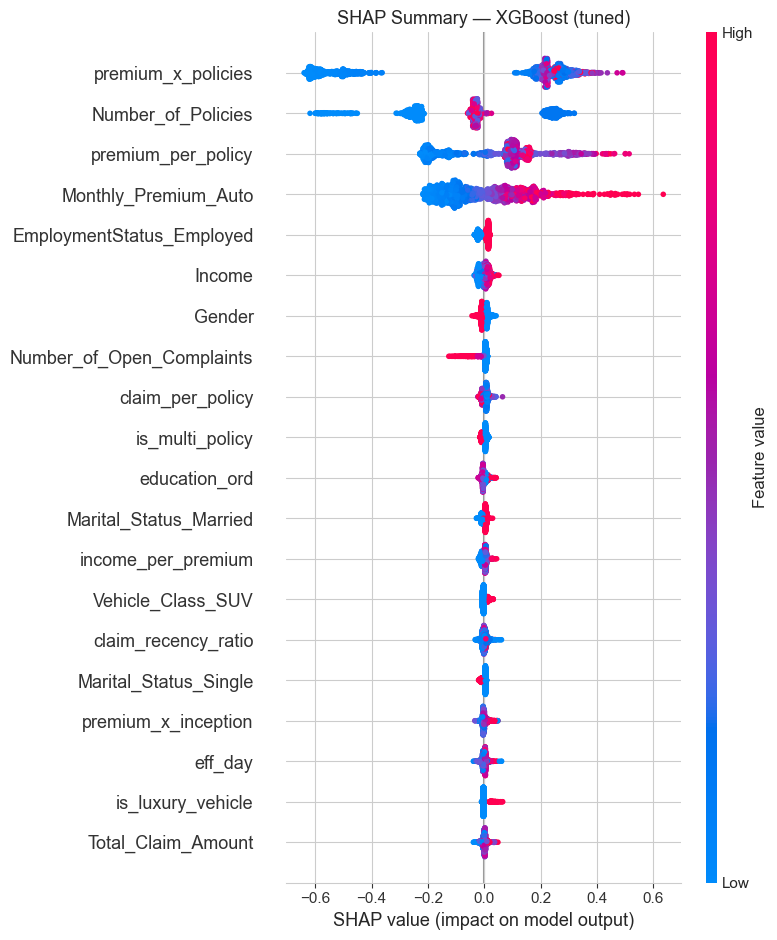

In [40]:
fig, ax = plt.subplots(figsize=(10, 10))
shap.summary_plot(shap_values, X_test_tree_df, max_display=20, show=False)
plt.title('SHAP Summary — XGBoost (tuned)', fontsize=13)
plt.tight_layout()
plt.show()

                  Feature  Mean |SHAP|
       premium_x_policies       0.3445
       Number_of_Policies       0.1777
       premium_per_policy       0.1481
     Monthly_Premium_Auto       0.1232
EmploymentStatus_Employed       0.0158
                   Income       0.0125
                   Gender       0.0116
Number_of_Open_Complaints       0.0085
         claim_per_policy       0.0085
          is_multi_policy       0.0074


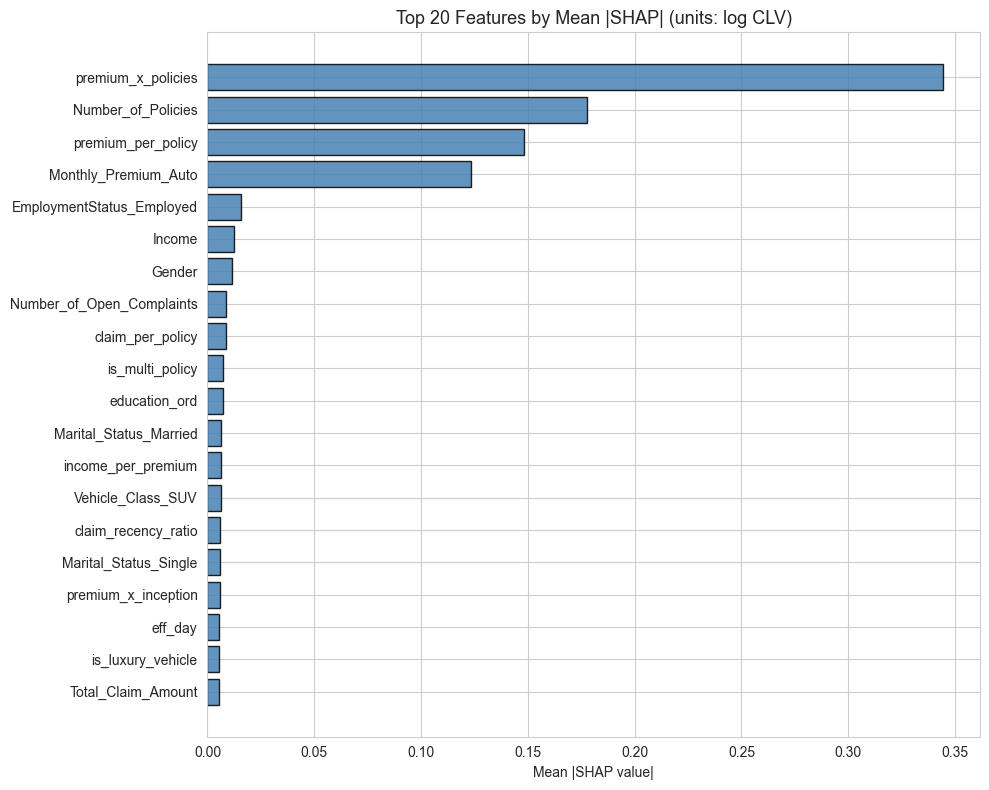

In [41]:
# Bar chart of mean |SHAP|
shap_importance = pd.DataFrame({
    'Feature': tree_feature_names,
    'Mean |SHAP|': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean |SHAP|', ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top = shap_importance.head(20)
ax.barh(top['Feature'], top['Mean |SHAP|'], color='steelblue', edgecolor='black', alpha=0.85)
print(top.head(10).round(4).to_string(index=False))
ax.set_title('Top 20 Features by Mean |SHAP| (units: log CLV)', fontsize=13)
ax.set_xlabel('Mean |SHAP value|')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

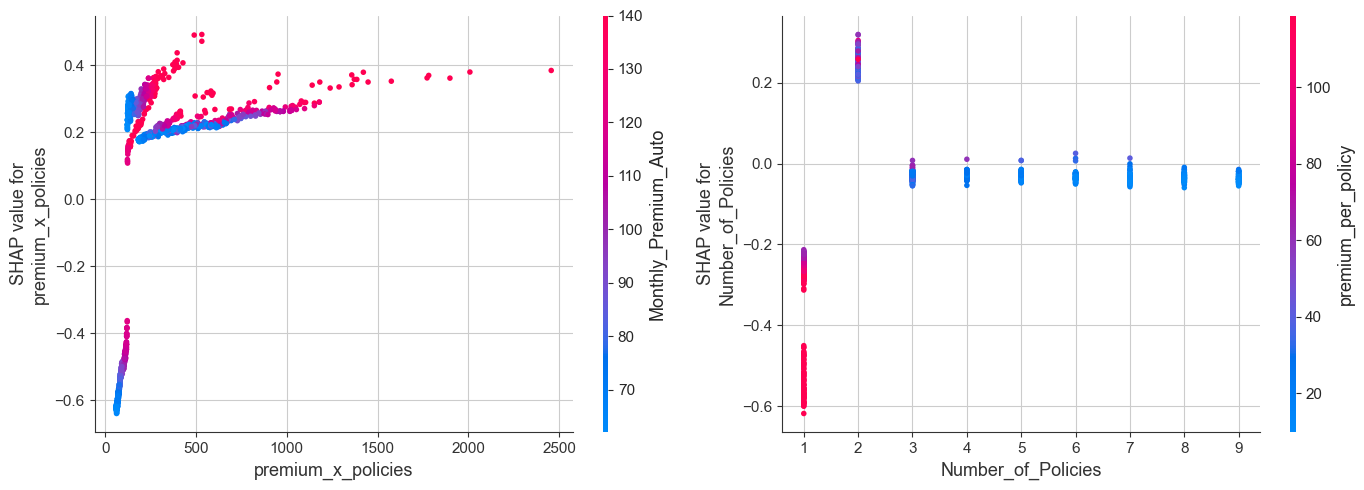

In [42]:
# Dependence plots for the top two numeric drivers
top_feats = [f for f in shap_importance['Feature'] if f in numeric_features][:2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, f in zip(axes, top_feats):
    shap.dependence_plot(f, shap_values, X_test_tree_df, ax=ax, show=False)
plt.tight_layout()
plt.show()

---
# 15. PCA Visualization

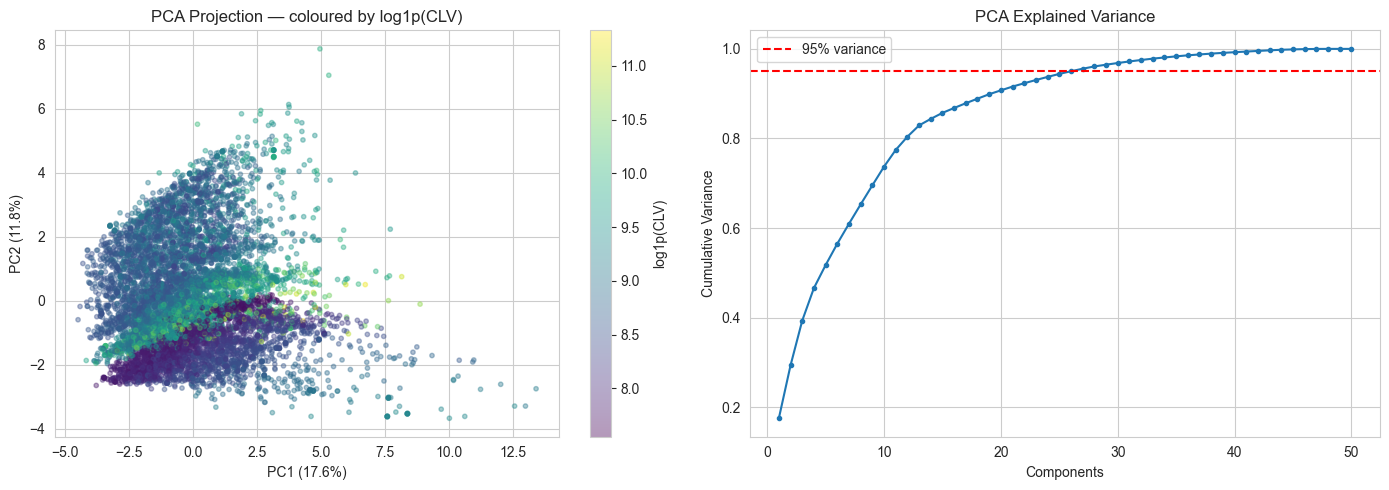

Components for 95% variance: 26 of 50


In [43]:
from sklearn.decomposition import PCA

X_processed = linear_preprocessor.transform(X)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_processed)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter coloured by the (continuous) target
scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', alpha=0.4, s=10)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PCA Projection — coloured by log1p(CLV)')
plt.colorbar(scatter, ax=axes[0], label='log1p(CLV)')

# Cumulative variance
pca_full = PCA(random_state=RANDOM_STATE).fit(X_processed)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
axes[1].plot(range(1, len(cumvar) + 1), cumvar, marker='o', markersize=3)
axes[1].axhline(0.95, color='red', linestyle='--', label='95% variance')
axes[1].set_xlabel('Components')
axes[1].set_ylabel('Cumulative Variance')
axes[1].set_title('PCA Explained Variance')
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Components for 95% variance: {np.argmax(cumvar >= 0.95) + 1} of {X_processed.shape[1]}")

---
# 16. Final Summary

In [44]:
print('=' * 100)
print('ALL MODELS — TEST SET')
print('=' * 100)
print(results_df.to_string(index=False, float_format='{:.4f}'.format))
print()

# Timing
total_elapsed = time.perf_counter() - _t0_notebook
print('=' * 100)
print('TIMING SUMMARY')
print('=' * 100)
timing_labels = [
    'Data Loading & Cleaning', 'Feature Engineering',
    'Phase 1 — Baselines',
    'P2: ElasticNet tuning', 'P2: RF tuning', 'P2: HGB tuning',
    'Phase 2 — Tuned Sklearn',
    'P3: XGBoost Optuna', 'P3: LightGBM Optuna', 'P3: CatBoost Optuna',
    'P3: Final fits', 'P3: Stacking',
    'Phase 3 — Advanced Models',
    'Prediction intervals', 'SHAP',
]
for label in timing_labels:
    if label in _timers:
        elapsed = _timers[label]
        m, s = divmod(elapsed, 60)
        indent = '    ' if not label.startswith(('Phase', 'Data', 'Feature', 'SHAP', 'Prediction')) else ''
        print(f"  {indent}{label:<35s} {int(m):>2d}m {s:>5.1f}s")
m, s = divmod(total_elapsed, 60)
print(f"  {'TOTAL':<35s} {int(m):>2d}m {s:>5.1f}s")
print('=' * 100)

ALL MODELS — TEST SET
                 Model  RMSE (log)  MAE (log)  R2 (log)   MAE ($)  R2 ($)  CV RMSE (log)
      P1: Dummy (mean)      0.6659     0.5333   -0.0018 4176.5481 -0.0494         0.6496
 P1: Linear Regression      0.2839     0.1984    0.8179 2201.1634  0.3623         0.2895
     P1: Random Forest      0.2007     0.0925    0.9090 1394.6496  0.6759         0.1966
 P1: Gradient Boosting      0.2078     0.1089    0.9025 1571.6826  0.6553         0.2045
P2: ElasticNet (tuned)      0.2842     0.1979    0.8175 2188.8474  0.3717         0.2893
        P2: RF (tuned)      0.1975     0.0935    0.9118 1405.7794  0.6797         0.1940
       P2: HGB (tuned)      0.1988     0.0974    0.9107 1435.6729  0.6800         0.1976
   P3: XGBoost (tuned)      0.2008     0.0982    0.9090 1463.8361  0.6760         0.1972
  P3: LightGBM (tuned)      0.1995     0.0931    0.9101 1414.0172  0.6713         0.1956
  P3: CatBoost (tuned)      0.1982     0.0987    0.9113 1424.9841  0.6869         0.1935

### Conclusions

**Phase 1 -> Phase 2 (tuning):**
- Tuning improves test RMSE (log) by only 0.003 for the best tree model (0.201 -> 0.198) and nothing for the linear model. There is no cheap, large gain left after Phase 1.
- Runtime: ~9s -> ~1.6min.

**The big gain is trees vs linear (already in Phase 1):**
- Linear Regression R² (log) 0.82 -> Random Forest 0.91, RMSE 0.284 -> 0.201. Interactions between premium and number of policies carry the signal.

**Phase 2 -> Phase 3 (marginal gain):**
- XGBoost / LightGBM / CatBoost + Optuna reach RMSE (log) 0.198-0.201; stacking reaches 0.197. That is about -0.0005 against the best Phase 2 model, i.e. noise, for ~2.4 min of extra runtime and three more libraries to maintain.

**The ceiling is in the data, not the model.**
- Every strong model converges to R² (log) ~0.91 and R² ($) ~0.68. The residuals show why: customers with exactly 2 policies have an unexplained, bimodal CLV-per-premium multiplier that none of the 33 features can predict, and those customers produce most of the squared error.
- Further gains need new information about those customers (e.g. what distinguishes the two multiplier clusters), not more model tuning.

**Top CLV drivers (consistent across model families):**
1. `premium_x_policies`, `Number_of_Policies`, `premium_per_policy` and `Monthly_Premium_Auto` together carry nearly all of the SHAP importance (mean |SHAP| 0.12-0.34 each)
2. Number of policies behaves as three regimes (1, 2, 3+), which is why the engineered premium x policies features dominate
3. Everything else (employment status, income, gender, complaints, claims per policy) is an order of magnitude smaller (mean |SHAP| under 0.02)

**Caveat:** The clean multiplicative structure of CLV in this dataset looks synthetic. Treat the absolute accuracy (R² ~0.91) as a property of this dataset, not as a benchmark for real insurance data.